# Task 1 Analysis of Drug–Target Datasets

**Objective:** Explore score distributions and observation of the drug-target pairs. Explain the main features and key differences between DAVIS and KIBA.

In [1]:
import json
import os
import pickle
import urllib.request

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

os.makedirs("figures", exist_ok=True)
os.makedirs("data/processed", exist_ok=True)

C:\Users\ewong\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Download Two Datasets and Overview

Download both datasets into data/ of your project folder. Show necessary examples in table(s) to reflect the data format.

In [2]:
# Source 1: Kaggle
kagglehub.dataset_download("rajaryan2315/davis-and-kiba-datasets", output_dir="data/source1")

# Source 2: DeepDTA GitHub
url = "https://raw.githubusercontent.com/hkmztrk/DeepDTA/master/data"
for name in ["davis", "kiba"]:
    os.makedirs(f"data/source2/{name}", exist_ok=True)
    for file in ["Y", "ligands_can.txt", "proteins.txt"]:
        path = f"data/source2/{name}/{file}"
        if not os.path.exists(path):
            urllib.request.urlretrieve(f"{url}/{name}/{file}", path)

In [3]:
def load_source2(name):
    folder = f"data/source2/{name}/"
    ligands = json.load(open(folder + "ligands_can.txt"))         # {ligand_id: SMILES}
    targets = json.load(open(folder + "proteins.txt"))            # {target_id: sequence}
    Y = pickle.load(open(folder + "Y", "rb"), encoding="latin1")  # matrix: ligands x targets

    matrix = pd.DataFrame(Y, index=list(ligands), columns=list(targets))
    # One row per (ligand, target) pair; NaN = not measured, so drop it
    df = matrix.stack().dropna().reset_index()
    df.columns = ["ligand_id", "target_id", "score"]
    df["smiles"] = df["ligand_id"].map(ligands)
    df["sequence"] = df["target_id"].map(targets)
    return matrix, df


davis_matrix, davis = load_source2("davis")
kiba_matrix, kiba = load_source2("kiba")

In [4]:
# Raw matrix format: DAVIS is Kd in nM, KIBA has NaN for unmeasured pairs
display(davis_matrix.iloc[:5, :5])
display(kiba_matrix.iloc[:5, :5])

,AAK1,ABL1(E255K),ABL1(F317I),ABL1(F317I)p,ABL1(F317L)
11314340,43.0,10000.0,10000.0,10000.0,10000.00
24889392,10000.0,10000.0,10000.0,10000.0,10000.00
11409972,10000.0,75.0,1.9,13.0,0.77
11338033,10000.0,10000.0,10000.0,10000.0,10000.00
10184653,10000.0,420.0,2900.0,750.0,580.00


,O00141,O00311,O00329,O00418,O00444
CHEMBL1087421,11.1,NaN,NaN,NaN,NaN
CHEMBL1088633,11.1,NaN,NaN,NaN,NaN
CHEMBL1090360,12.1,11.999998,NaN,NaN,NaN
CHEMBL1688215,11.1,NaN,NaN,NaN,NaN
CHEMBL1765781,12.1,NaN,NaN,NaN,NaN


In [5]:
# Long format: one row per ligand-target pair
display(davis.head())
display(kiba.head())

,ligand_id,target_id,score,smiles,sequence
0,11314340,AAK1,43.0,CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC...,MKKFFDSRREQGGSGLGSGSSGGGGSTSGLGSGYIGRVFGIGRQQV...
1,11314340,ABL1(E255K),10000.0,CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC...,PFWKILNPLLERGTYYYFMGQQPGKVLGDQRRPSLPALHFIKGAGK...
2,11314340,ABL1(F317I),10000.0,CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC...,PFWKILNPLLERGTYYYFMGQQPGKVLGDQRRPSLPALHFIKGAGK...
3,11314340,ABL1(F317I)p,10000.0,CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC...,PFWKILNPLLERGTYYYFMGQQPGKVLGDQRRPSLPALHFIKGAGK...
4,11314340,ABL1(F317L),10000.0,CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC...,PFWKILNPLLERGTYYYFMGQQPGKVLGDQRRPSLPALHFIKGAGK...


,ligand_id,target_id,score,smiles,sequence
0,CHEMBL1087421,O00141,11.1,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MTVKTEAAKGTLTYSRMRGMVAILIAFMKQRRMGLNDFIQKIANNS...
1,CHEMBL1087421,O14920,11.1,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MSWSPSLTTQTCGAWEMKERLGTGGFGNVIRWHNQETGEQIAIKQC...
2,CHEMBL1087421,O15111,11.1,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MERPPGLRPGAGGPWEMRERLGTGGFGNVCLYQHRELDLKIAIKSC...
3,CHEMBL1087421,P00533,11.1,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MRPSGTAGAALLALLAALCPASRALEEKKVCQGTSNKLTQLGTFED...
4,CHEMBL1087421,P04626,11.1,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MELAALCRWGLLLALLPPGAASTQVCTGTDMKLRLPASPETHLDML...


In [6]:
pd.DataFrame({
    "DAVIS": [davis_matrix.shape[0], davis_matrix.shape[1], len(davis), "Kd (nM)"],
    "KIBA": [kiba_matrix.shape[0], kiba_matrix.shape[1], len(kiba), "KIBA score"],
}, index=["Ligands", "Targets", "Observed pairs", "Score"])

,DAVIS,KIBA
Ligands,68,2111
Targets,442,229
Observed pairs,30056,118254
Score,Kd (nM),KIBA score


## 2. Data Cleaning

Apply fundamental cleaning methods, e.g., exclude non-finite scores and require positive DAVIS Kd. Keep valid and necessary extreme or zero scores. You also need to conduct necessary deduplication or average the scores of repeated samples. Report original and deduplicated ligand, target and observed-pair counts in table(s).

In [7]:
# Exclude non-finite scores, require positive Kd
print("DAVIS rows before:", len(davis))
davis = davis[np.isfinite(davis["score"]) & (davis["score"] > 0)].copy()
print("DAVIS rows after: ", len(davis))

print("KIBA rows before:", len(kiba))
kiba = kiba[np.isfinite(kiba["score"])].copy()
print("KIBA rows after: ", len(kiba))

# DAVIS: convert Kd (nM) to pKd
davis["score"] = 9 - np.log10(davis["score"])

DAVIS rows before: 30056
DAVIS rows after:  30056
KIBA rows before: 118254
KIBA rows after:  118254


In [8]:
# Extreme values are kept, only counted
print("DAVIS pairs at Kd = 10000 nM (pKd = 5):", (davis["score"] == 5).sum(), f"({(davis['score'] == 5).mean():.1%})")
print("KIBA pairs with score 0:", (kiba["score"] == 0).sum())
print("KIBA lowest scores:")
display(kiba.nsmallest(10, "score")[["ligand_id", "target_id", "score"]])

DAVIS pairs at Kd = 10000 nM (pKd = 5): 20931 (69.6%)
KIBA pairs with score 0: 1
KIBA lowest scores:


,ligand_id,target_id,score
103943,CHEMBL373751,P53350,0.000000
103939,CHEMBL373751,P00533,1.100000
103940,CHEMBL373751,P04626,1.100000
103941,CHEMBL373751,P49840,1.300000
103942,CHEMBL373751,P49841,1.300000
103944,CHEMBL373751,P53779,1.300000
103946,CHEMBL373751,Q15759,1.300000
103937,CHEMBL373751,O14920,6.100000
103938,CHEMBL373751,O15111,6.100000
103945,CHEMBL373751,Q14164,6.100004


In [9]:
# Duplicates: different IDs with the same SMILES / sequence
for name, df in [("DAVIS", davis), ("KIBA", kiba)]:
    print(name, "ligand IDs:", df["ligand_id"].nunique(), "unique SMILES:", df["smiles"].nunique())
    print(name, "target IDs:", df["target_id"].nunique(), "unique sequences:", df["sequence"].nunique())

# Example: DAVIS targets that share one sequence (mutants of the same kinase)
shared = davis.groupby("sequence")["target_id"].unique()
shared[shared.str.len() > 1].reset_index(drop=True).head()

DAVIS ligand IDs: 68 unique SMILES: 68
DAVIS target IDs: 442 unique sequences: 379
KIBA ligand IDs: 2111 unique SMILES: 2068


KIBA target IDs: 229 unique sequences: 229


0                                  [BRAF, BRAF(V600E)]
1            [RET, RET(M918T), RET(V804L), RET(V804M)]
2                               [LRRK2, LRRK2(G2019S)]
3                       [CDK4-cyclinD1, CDK4-cyclinD3]
4    [RSK3(KinDom.1-N-terminal), RSK3(KinDom.2-C-te...
Name: target_id, dtype: object

In [10]:
def deduplicate(df):
    df = df.copy()
    # IDs with the same SMILES / sequence get one shared ID (the first one)
    df["ligand_id"] = df.groupby("smiles")["ligand_id"].transform("first")
    df["target_id"] = df.groupby("sequence")["target_id"].transform("first")
    # Then average the scores of repeated pairs
    return df.groupby(["ligand_id", "target_id"], as_index=False).agg(
        smiles=("smiles", "first"), sequence=("sequence", "first"), score=("score", "mean"))


davis_dedup = deduplicate(davis)
kiba_dedup = deduplicate(kiba)

In [11]:
counts = pd.DataFrame({
    "DAVIS original": [davis["ligand_id"].nunique(), davis["target_id"].nunique(), len(davis)],
    "DAVIS deduplicated": [davis_dedup["ligand_id"].nunique(), davis_dedup["target_id"].nunique(), len(davis_dedup)],
    "KIBA original": [kiba["ligand_id"].nunique(), kiba["target_id"].nunique(), len(kiba)],
    "KIBA deduplicated": [kiba_dedup["ligand_id"].nunique(), kiba_dedup["target_id"].nunique(), len(kiba_dedup)],
}, index=["Ligands", "Targets", "Observed pairs"])
counts

,DAVIS original,DAVIS deduplicated,KIBA original,KIBA deduplicated
Ligands,68,68,2111,2068
Targets,442,379,229,229
Observed pairs,30056,25772,118254,117657


In [12]:
# Save for Task 2 and Task 3
davis_dedup.to_csv("data/processed/davis_clean.csv", index=False)
kiba_dedup.to_csv("data/processed/kiba_clean.csv", index=False)

## 3. Visualization

**Heatmaps:** Plot a separate ligand–target heatmap for each dataset: DAVIS pKd and supplied KIBA scores. Clearly distinguish missing entries.

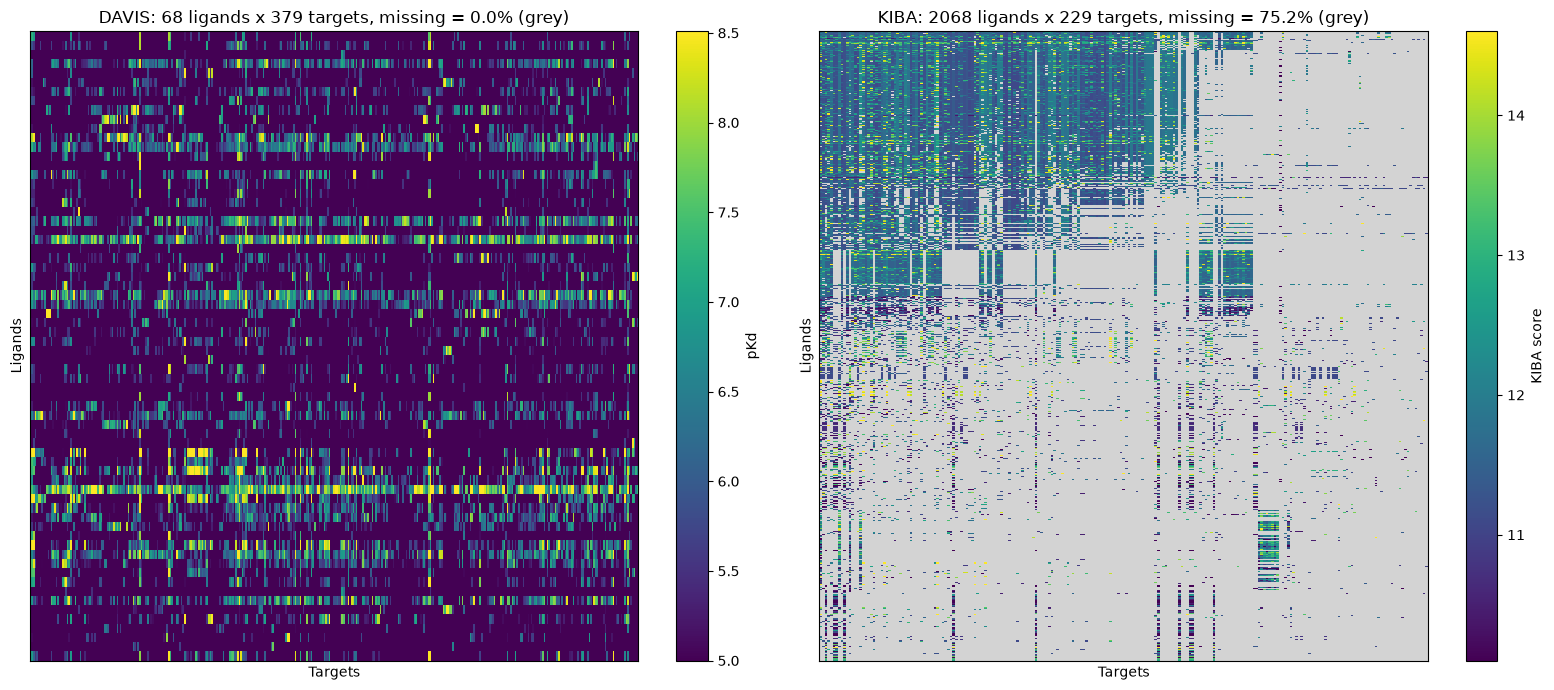

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, name, df in [(axes[0], "DAVIS", davis_dedup), (axes[1], "KIBA", kiba_dedup)]:
    matrix = df.pivot(index="ligand_id", columns="target_id", values="score")
    # Sort rows and columns by number of measurements
    matrix = matrix.loc[matrix.notna().sum(axis=1).sort_values(ascending=False).index,
                        matrix.notna().sum(axis=0).sort_values(ascending=False).index]

    cmap = plt.get_cmap("viridis").copy()
    cmap.set_bad("lightgrey")  # missing entries in grey
    im = ax.imshow(matrix, aspect="auto", cmap=cmap, interpolation="nearest",
                   vmin=np.nanpercentile(matrix, 1), vmax=np.nanpercentile(matrix, 99))
    fig.colorbar(im, ax=ax, label="pKd" if name == "DAVIS" else "KIBA score")

    missing = matrix.isna().mean().mean()
    ax.set_title(f"{name}: {matrix.shape[0]} ligands x {matrix.shape[1]} targets, missing = {missing:.1%} (grey)")
    ax.set_xlabel("Targets")
    ax.set_ylabel("Ligands")
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.savefig("figures/task1_heatmaps.png", dpi=200)
plt.show()

**Distributions:** Plot the observed score distribution for each dataset, preferably using KDE. Label the score scale and density axis.

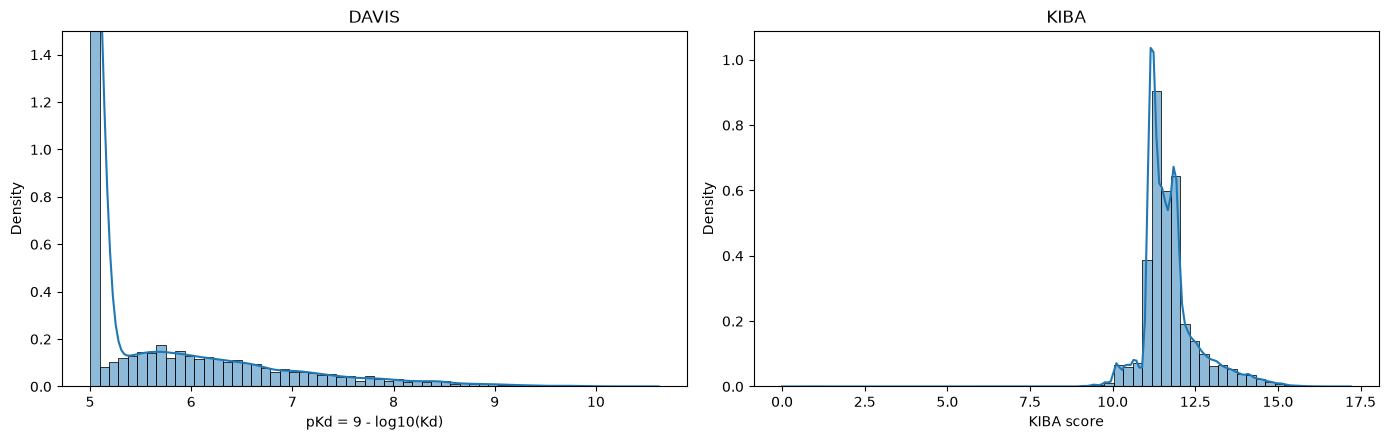

,DAVIS,KIBA
count,25772.000,117657.000
mean,5.397,11.721
std,0.811,0.834
min,5.000,0.000
25%,5.000,11.200
50%,5.000,11.527
75%,5.398,11.924
max,10.620,17.200


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.histplot(davis_dedup["score"], bins=60, stat="density", kde=True, ax=axes[0])
axes[0].set_ylim(0, 1.5)  # the bar at pKd 5 is much taller (cut off)
axes[0].set_xlabel("pKd = 9 - log10(Kd)")
axes[0].set_ylabel("Density")
axes[0].set_title("DAVIS")

sns.histplot(kiba_dedup["score"], bins=60, stat="density", kde=True, ax=axes[1])
axes[1].set_xlabel("KIBA score")
axes[1].set_ylabel("Density")
axes[1].set_title("KIBA")

plt.tight_layout()
plt.savefig("figures/task1_distributions.png", dpi=200)
plt.show()

pd.DataFrame({"DAVIS": davis_dedup["score"].describe(), "KIBA": kiba_dedup["score"].describe()}).round(3)

**Any analytical tools you learned in this course:** Include helpful methods you think that can support your findings on ligand and target properties.

KIBA sparsity: 75.2%


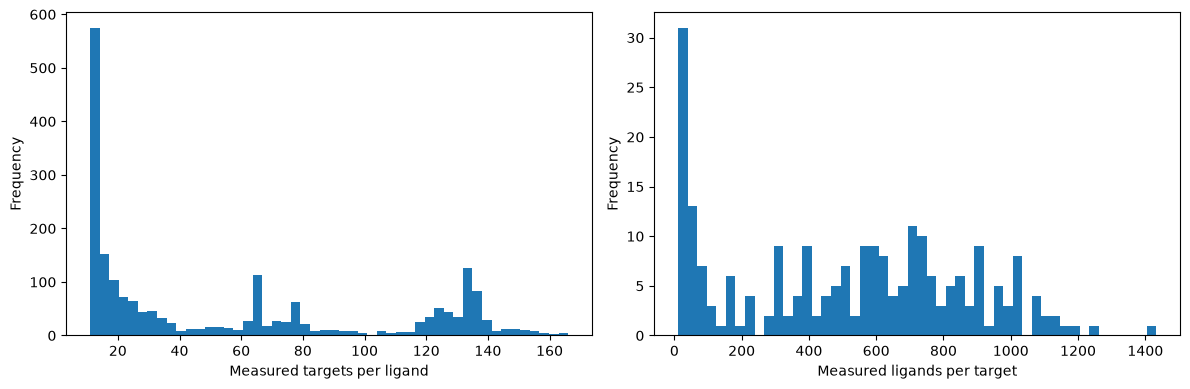

In [15]:
# KIBA sparsity = missing positions / all matrix positions
n_lig, n_tgt = kiba_dedup["ligand_id"].nunique(), kiba_dedup["target_id"].nunique()
print(f"KIBA sparsity: {1 - len(kiba_dedup) / (n_lig * n_tgt):.1%}")

# How many measurements each KIBA ligand and target has
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
kiba_dedup["ligand_id"].value_counts().plot.hist(bins=50, ax=axes[0])
axes[0].set_xlabel("Measured targets per ligand")
kiba_dedup["target_id"].value_counts().plot.hist(bins=50, ax=axes[1])
axes[1].set_xlabel("Measured ligands per target")
plt.tight_layout()
plt.savefig("figures/task1_kiba_counts.png", dpi=200)
plt.show()

In [16]:
# Strong binding: DAVIS pKd >= 7, KIBA score >= 12.1 (thresholds from He et al., 2017, SimBoost)
davis_dedup["strong"] = davis_dedup["score"] >= 7
kiba_dedup["strong"] = kiba_dedup["score"] >= 12.1
print(f"Strong pairs: DAVIS {davis_dedup['strong'].mean():.1%}, KIBA {kiba_dedup['strong'].mean():.1%}")

# Ligands that bind the largest share of their targets strongly
print("DAVIS:")
display(davis_dedup.groupby("ligand_id")["strong"].mean().sort_values(ascending=False).head())
print("KIBA (ligands with at least 50 measurements):")
kiba_lig = kiba_dedup.groupby("ligand_id")["strong"].agg(["mean", "count"])
display(kiba_lig[kiba_lig["count"] >= 50].sort_values("mean", ascending=False).head())

Strong pairs: DAVIS 6.8%, KIBA 21.0%
DAVIS:


ligand_id
44259       0.569921
126565      0.445910
16038120    0.255937
11984591    0.221636
42642645    0.221636
Name: strong, dtype: float64

KIBA (ligands with at least 50 measurements):


,mean,count
ligand_id,,
CHEMBL1988581,1.000000,66
CHEMBL215803,1.000000,66
CHEMBL1765781,0.921875,64
CHEMBL1980995,0.913386,127
CHEMBL1980407,0.878788,66


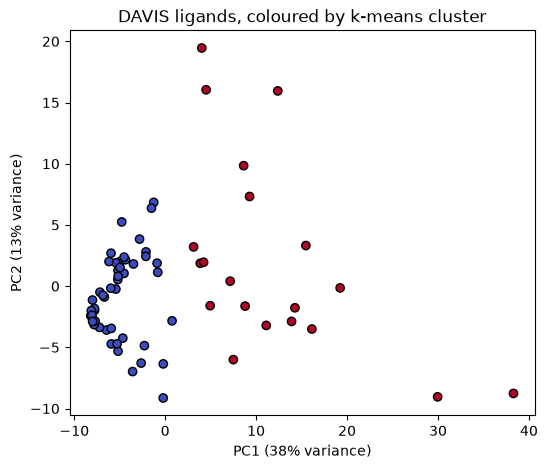

mean pKd      
           count  mean
cluster               
0             48  5.18
1             20  5.93

In [17]:
# PCA + k-means on DAVIS: each ligand is a vector of its pKd over all targets
X = davis_dedup.pivot(index="ligand_id", columns="target_id", values="score")

pca = PCA(n_components=2)
X_2d = pca.fit_transform(X)
clusters = KMeans(n_clusters=2, n_init=10, random_state=0).fit_predict(X)

plt.figure(figsize=(6, 5))
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=clusters, cmap="coolwarm", edgecolor="k")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} variance)")
plt.title("DAVIS ligands, coloured by k-means cluster")
plt.savefig("figures/task1_davis_pca.png", dpi=200)
plt.show()

# Average pKd per cluster
pd.DataFrame({"cluster": clusters, "mean pKd": X.mean(axis=1).values}).groupby("cluster").agg(["count", "mean"]).round(2)